# <span style="color:darkblue"> Lecture 12a: Logistic Regression for Classification
 </span>

<font size = "5">

In this lecture we will focus on preciction with binary data, <br>
focusing on the logistic regression model. We will learn how to 

- Conduct statistical infernece
- Classify predictions and evaluate performance


# <span style="color:darkblue"> I. Import Libraries </span>

<font size= "5">

In addition to standard packages, you will need to have installed:

- ``` scikit-learn ```
- ``` statsmodels ```
- ``` maketables ```

If they are not already installed, do so using the instructions <br>
from previous lectures.

In [16]:
# The "pandas" library is used for processing datasets
# The "numpy" is for numeric observations and random numbers
# The "matplotlib.pyplot" library is for creating graphs

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# We will use the "sklearn" package

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# Import statsmodels and regression table tools
import statsmodels.api as sm
import statsmodels.formula.api as smf
import maketables as mt


# This is used to create data matrices
import patsy

<font size = "5" >

### <span style="color:darkblue">  II. Example: Diffusion of microfinance </span>

Banerjee et al. (2013) explored the effects of a marketing <br>
campaign in rural villages in Karnataka, India, on the   <br>
probability of requesting a microfinance loan.

https://www.science.org/doi/10.1126/science.1236498

We will use their data today.

<font size = "5">

The outcome variable <br>

$\quad Y_i = \text{RequestLoan}_i $

<font size = "5">

The predictor vector:

$\quad X_i = \begin{bmatrix} 1 \\ \text{ReceivedInfo}_i \\ \text{OwnsHouse}_i \\ \text{HomeNumRooms}_i \end{bmatrix} $



# <span style="color:darkblue"> III. Prepare Data </span>


<font size = "5">

Read microfinance data

In [17]:
dataset = pd.read_csv("data_raw/microfinance_data.csv")

<font size = "5">

Create "y" and "X" matrices from a formula. This allows for:

- Interactions
- Factors
- Polynomials

In [18]:
y, X = \
    patsy.dmatrices('request_loan ~ 1 + received_info + owns_house',
                       dataset, return_type='dataframe')
y = np.ravel(y)

# <span style="color:darkblue"> IV. Fit model and produce regression tables

<font size = "5">

In the logistic regression model, <br>
models the probability of taking out a loan as

$ \mathbb{P}(Y_i = 1 \mid X_i) = \frac{e^{g(X_i)}}{1+e^{g(X_i)}},$

where

$g(X_i) = \beta_0 + \beta_1 \text{ReceivedInfo}_i + \beta_2 \text{OwnsHouse}_i + \beta_3 \text{HomeNumRooms}_i$


<font size = "5">


Next we present three equivalent ways (a)-(c) to estimate this model

<font size = "5">

(a) Estimate the logistic regression using the formula interface on all observations included in the model.

In [19]:
# HC1 robust standard errors are used for the regression table.

table_model = smf.logit(
    'request_loan ~ 1 + received_info + owns_house',
    data=dataset
).fit(cov_type='HC1')
mt.ETable([table_model])

Optimization terminated successfully.
         Current function value: 0.473568
         Iterations 5


<maketables.mtable.MTable.__repr__.<locals>.DualOutput at 0x238fc3d5750>

<font size = "5">

(b) Fit the same full-sample model with the non-formula interface. 

In [20]:
# HC1 robust standard errors are used for the regression table.

table_model_matrix = sm.Logit(y, X).fit(cov_type='HC1')
mt.ETable([table_model_matrix])

Optimization terminated successfully.
         Current function value: 0.473568
         Iterations 5


<maketables.mtable.MTable.__repr__.<locals>.DualOutput at 0x238fc34c110>

<font size = "5">

(c) Fit scikit-learn's unpenalized logistic regression on the full data and print its coefficients beside the `statsmodels` coefficients. Turning off the separate intercept makes both models comparable.

In [21]:
# Estimate logistic with sklearn
sklearn_logit = LogisticRegression(
    penalty=None, fit_intercept=False, solver='lbfgs',
    max_iter=1000, tol=1e-10
).fit(X, y)

print('Statsmodels coefficients:')
print(table_model_matrix.params)

print('Scikit-learn coefficients:')
print(pd.Series(sklearn_logit.coef_.ravel(), index=X.columns))

Statsmodels coefficients:
Intercept       -1.448411
received_info    0.379671
owns_house      -0.114925
dtype: float64
Scikit-learn coefficients:
Intercept       -1.448411
received_info    0.379671
owns_house      -0.114925
dtype: float64


<font size = "5">

```statsmodels``` and ```sklearn``` have distinct advantages

- ```statsmodels``` is slightly better for hypothesis testing and producing <br>
regression tables
- ```sklearn``` is slightly better for prediction diagnostics and includes <br>
a wider array of models (including machine learning)

# <span style="color:darkblue"> V. Sample-splitting for model diagnostics </span>


<font size = "5">

Fit a classifier on the training sample; use the test sample for out-of-sample diagnostics.

<font size = "5">

Split the data into training and test

<font size = "3">

- "test_size" is a number between 0 and 1 that control the relative <br>
proportions of the training and test datasets.
- "random_state" is a seed that ensures that the training and test datasets <br>
can be replicated

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
           X, y, test_size=0.5, random_state=42)

In [23]:
model = LogisticRegression(
    penalty=None, fit_intercept=False, solver='lbfgs',
    max_iter=1000, tol=1e-10
).fit(X_train, y_train)

<font size = "5">

Obtain vector of predicted probabilites on test set

Text(0.5, 1.0, 'Predicted Probabilities on Test Set')

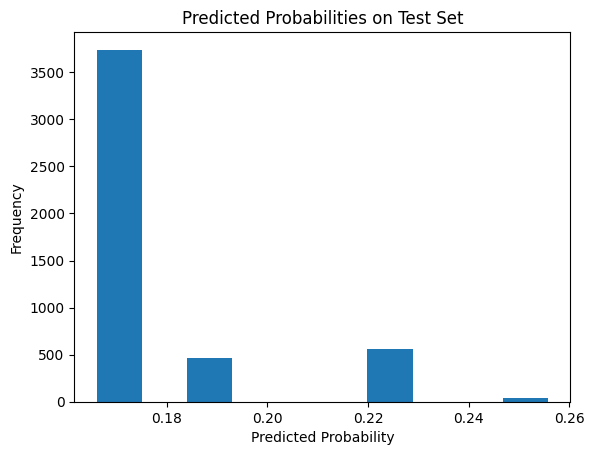

In [24]:
# Obtain predicted probabilities
mat_probabilities = pd.DataFrame(model.predict_proba(X_test))

# Obtain probabilites for the event 1 
# (This is the second column of "mat_probabilities")
vec_probabilities = mat_probabilities.iloc[:,1]

# Display results
plt.hist(x = vec_probabilities)
plt.xlabel("Predicted Probability")
plt.ylabel("Frequency")
plt.title("Predicted Probabilities on Test Set")

<font size = "5">

Classifying observations

- If probability is higher than 0.2 classify as 1
- Can change threshold

In [25]:
bins_y = [0,0.2, 1]
labels_y = [0,1]

predicted_labels = pd.cut(vec_probabilities,
                              bins = bins_y,
                              right = True,
                              labels = labels_y)

<font size = "5">

Obtain a confusion matrix

In [26]:
cm = confusion_matrix(y_test, predicted_labels)
cm

array([[3442,  449],
       [ 762,  146]])

<font size = "5">

Display confusion matrix

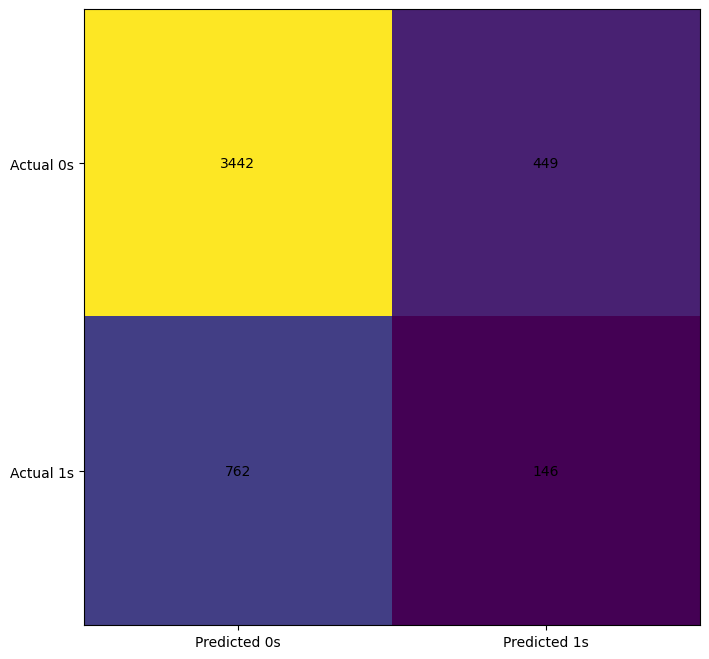

In [27]:

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(cm)
ax.grid(False)
ax.xaxis.set(ticks=(0, 1), ticklabels=('Predicted 0s', 'Predicted 1s'))
ax.yaxis.set(ticks=(0, 1), ticklabels=('Actual 0s', 'Actual 1s'))
ax.set_ylim(1.5, -0.5)
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center')
plt.show()

# <span style="color:darkblue"> VI. Exercises </span>

<font size = "5">

Try it yourself

- Change the classification threshold
- How does this change the classification accuracy?
- Create a for-loop evaluating the accuracy over different thresholds


Thresholds: [0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9]
Accuracies: [np.float64(0.18920608460095853), np.float64(0.7476557616170035), np.float64(0.8107939153990414), np.float64(0.8107939153990414), np.float64(0.8107939153990414), np.float64(0.8107939153990414), np.float64(0.8107939153990414), np.float64(0.8107939153990414), np.float64(0.8107939153990414)]


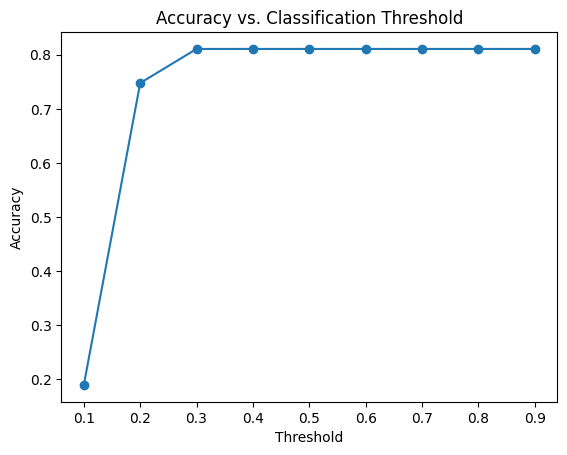

Optimal Threshold: 0.30000000000000004


In [ ]:
# Write your own code

thresholds = np.arange(0.1, 1.0, 0.1)
accuracies = []

for threshold in thresholds:
    y_pred = (vec_probabilities >= threshold).astype(int)
    accuracy = np.mean(y_pred == y_test)
    accuracies.append(accuracy)

print("Thresholds:", thresholds)
print("Accuracies:", accuracies)

# Plot the results
plt.plot(thresholds, accuracies, marker='o')
plt.xlabel('Threshold')
plt.ylabel('Accuracy')
plt.title('Accuracy vs. Classification Threshold')
plt.show()

# Find the optimal threshold
optimal_threshold = thresholds[np.argmax(accuracies)]
print("Optimal Threshold:", optimal_threshold)

# Use the optimal threshold for final predictions
y_pred_optimal = (vec_probabilities >= optimal_threshold).astype(int)

# - How does this change the classification accuracy?

# The classification accuracy changes as the threshold is adjusted. A lower threshold may increase the number
# of positive predictions, potentially improving recall but at the cost of precision. Conversely, a higher
# threshold may reduce false positives but could miss some true positives.

<font size = "5">

Try it yourself

- Add interactions between "Own rooms" and other independent variables
- Does this improve the classification accuracy?
 


In [ ]:
# Write your own code

# - Add interactions between "Own rooms" and other independent variables

if 'own_rooms' in dataset.columns:
    dataset['received_info_own_rooms'] = dataset['received_info'] * dataset['own_rooms']
    dataset['owns_house_own_rooms'] = dataset['owns_house'] * dataset['own_rooms']

    y_interaction, X_interaction = \
        patsy.dmatrices('request_loan ~ 1 + received_info + owns_house + received_info_own_rooms + owns_house_own_rooms',
                       dataset, return_type='dataframe')
    y_interaction = np.ravel(y_interaction)

# Does this improve the classification accuracy?


<font size = "5">